# Cavity fields test

Define RF cavities, generate their normalized Gaussian mode profiles, and inspect their placement and interpolation on the longitudinal solver grid.

This notebook is standalone. It uses the same beam operating point, cavity centers, and explicit domain as `meshgrid_test.ipynb`. Edit the input cell and **Run All**; no other notebook needs to run first.

The sequence is:

`CavityFieldMap.from_circuit_parameters(...)` → local `z_mm, e_z` per cavity → `CavityFields.calculate(...)` → global `ez, C3`.

**Scope:** standing-wave RF cavities with `nh >= 1`, Gaussian profiles, and no field-file import. No circuit solve, space-charge field, or particle tracking is performed. These Python checks do not yet establish agreement with MATLAB.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path for path in (
        current_directory,
        current_directory / "pyKlyC",
        current_directory.parent,
    )
    if (path / "src" / "solver" / "cavity_fields.py").exists()
)
sys.path.insert(0, str(project_directory / "src"))

from constants import c, eta0
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.cavity_field_map import CavityFieldMap
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.cavity_fields import CavityFields

np.set_printoptions(precision=6, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def show_table(headers, rows):
    text = "| " + " | ".join(headers) + " |\n"
    text += "| " + " | ".join("---" for _ in headers) + " |\n"
    for row in rows:
        text += "| " + " | ".join(str(value) for value in row) + " |\n"
    display(Markdown(text))

## 1. Define the beam, cavities, and grid

All per-cavity arrays have `Nc` entries in the same order as `cavities.names`.

| Parameters | Role in this notebook |
|---|---|
| `f0, RtoQ, M, s` | Generate each local Gaussian profile |
| `N` | Local field-map intervals; each map has `N + 1` samples |
| `zshift` | Move the local profile to the cavity center |
| `f, Nz, z0, L` and reference beam speed | Define the solver grid |
| `I0, U0, betae, k0` | Convert the interpolated `ez` into `C3` |
| `type, nh` | Select structure type and harmonic; all fields here are standing-wave RF |
| `Pin, Qin, Qext, gaman, Lsb, kai` | Stored circuit parameters, **not solved** here |

Use `0 < M < 1` and positive `f0, RtoQ` for this Gaussian construction. The default even `N = 200` gives 201 local samples, including the cavity center. `N` and `Nz` are different resolutions.

In [2]:
# Beam operating point, as in meshgrid_test
Nbeam = 1
rm1 = 0.0
rm2 = 6.0
rc = 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

# Cavity parameters, in cavity-column order
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
RtoQ = np.array([182.8959, 116.9999, 102.0570, 123.6318, 180.3864])
M = np.array([0.9225, 0.8930, 0.8192, 0.9518, 0.9325])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{kk + 1}" for kk in range(Nc))
N = 200

# Same explicit domain as meshgrid_test
z0 = -100.0
L = 3000.0
rcv = np.array([[z0, z0 + L], [1.0, 1.0]])
Nz = 256
Ns = 8
factorregion = 10.0

beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=100,
    Ntimes=10, Rlimit=1.0e-4, iterfactor=0.5,
    evolutionmethod=np.array([0.005, 2.0]),
    upstream_discard_distance_mm=0.0,
    efficiency_end_offset_mm=3.0 * rc,
)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

labels = {0: "input", 1: "bunching", -1: "output"}
colors = plt.get_cmap("tab10")(np.arange(Nc) % 10)

show_table(
    ["Column (Python)", "Name", "Type", "nh", "f0 [GHz]", "RtoQ [ohm]", "M", "zshift [mm]"],
    [
        [kk, name, labels[type[kk]], nh[kk], f0[kk], RtoQ[kk], M[kk], zshift[kk]]
        for kk, name in enumerate(cavities.names)
    ],
)
show_table(
    ["Cavity", "Qin", "Qext", "Pin [W]", "gaman", "Lsb [rad]"],
    [[f"C{kk+1}", Qin[kk], Qext[kk], Pin[kk], gaman[kk], f"{Lsb[kk]:.6f}"] for kk in range(Nc)],
)
print("kai =\n", kai)
print(f"Reference: U0={reference.U0:g} kV, I0={reference.I0:g} A, s={reference.s:.6f}")
print(f"Grid: {len(grid.zi)} points, dz={grid.dz:.6f} mm, zi=[{grid.zi[0]:g}, {grid.zi[-1]:g}] mm")

| Column (Python) | Name | Type | nh | f0 [GHz] | RtoQ [ohm] | M | zshift [mm] |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | guide_cavity_1 | input | 1 | 1.0 | 182.8959 | 0.9225 | 0.0 |
| 1 | guide_cavity_2 | bunching | 1 | 1.006 | 116.9999 | 0.893 | 480.0 |
| 2 | guide_cavity_3 | bunching | 1 | 1.016 | 102.057 | 0.8192 | 1630.0 |
| 3 | guide_cavity_4 | bunching | 1 | 1.03 | 123.6318 | 0.9518 | 2400.0 |
| 4 | guide_cavity_5 | output | 1 | 1.0 | 180.3864 | 0.9325 | 2730.0 |


| Cavity | Qin | Qext | Pin [W] | gaman | Lsb [rad] |
| --- | --- | --- | --- | --- | --- |
| C1 | 16428.0 | 334.0 | 60.0 | 0j | 3.141593 |
| C2 | 19768.0 | 95000.0 | 0.0 | 0j | 3.141593 |
| C3 | 19816.0 | 95000.0 | 0.0 | 0j | 3.141593 |
| C4 | 16970.0 | 95000.0 | 0.0 | 0j | 3.141593 |
| C5 | 14787.0 | 50.0 | 0.0 | 0j | 3.141593 |


kai =
 [[0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]]
Reference: U0=180 kV, I0=16 A, s=0.673146
Grid: 3806 points, dz=0.788436 mm, zi=[-100, 2900] mm


## 2. Generate local normalized field maps

The generator uses the following Gaussian, with its origin at the center of each cavity:

\[
k=\frac{\omega_0}{2s c\sqrt{-\ln M}}\quad[\mathrm{m}^{-1}],
\qquad
e_{zm}=k\sqrt{\frac{R/Q}{\eta_0\pi}\frac{\omega_0}{c}}\;1000^{-3/2},
\]
\[
e_z(z_{\mathrm{mm}})=e_{zm}
\exp\left[-\left(k\,10^{-3}z_{\mathrm{mm}}\right)^2\right].
\]

The local coordinate runs from \(-3000/k\) to \(+3000/k\) mm. This is **three Gaussian width parameters**, not three standard deviations; the profile at either endpoint is \(e^{-9}\) times its peak.

`e_z` is the energy-normalized on-axis mode profile, in \(\mathrm{mm}^{-3/2}\). It is not an electric field in V/m, and it is not rescaled to a peak of one. `RtoQ` must retain its amplitude information.

In the diagnostic equations below, `k0 = w0/c` is in 1/m, as inside the Gaussian generator. In contrast, `grid.k0` is in 1/mm. They represent the same vacuum wavenumber in different units.

| Cavity | Samples | Local limits [mm] | 1/k [mm] | Peak ezm [mm^-3/2] |
| --- | --- | --- | --- | --- |
| guide_cavity_1 | 201 | [-54.7333, 54.7333] | 18.2444 | 0.003119327 |
| guide_cavity_2 | 201 | [-64.4416, 64.4416] | 21.4805 | 0.002125377 |
| guide_cavity_3 | 201 | [-84.7031, 84.7031] | 28.2344 | 0.001517677 |
| guide_cavity_4 | 201 | [-41.5843, 41.5843] | 13.8614 | 0.003425826 |
| guide_cavity_5 | 201 | [-50.9444, 50.9444] | 16.9815 | 0.003328249 |


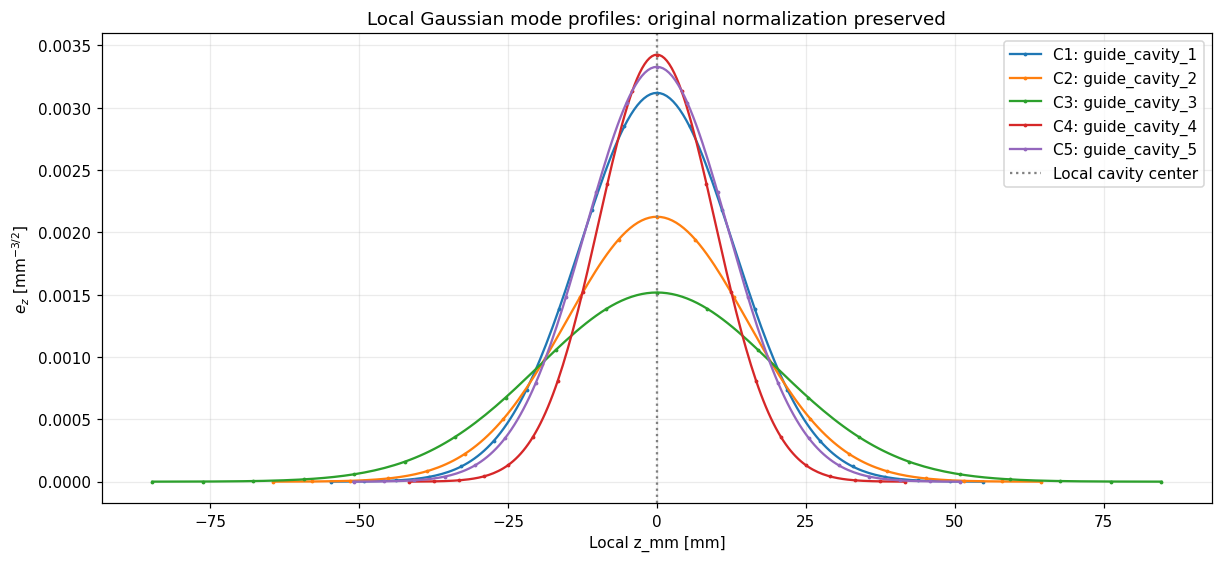

In [3]:
field_maps = CavityFieldMap.from_circuit_parameters(
    cavityname=cavities.names,
    f0=cavities.f0,
    RtoQ=RtoQ,
    M=M,
    s=reference.s,
    N=N,
)

# Analytical quantities for comparison with the generated profiles
w0 = 2.0 * np.pi * f0 * 1.0e9
k0 = w0 / c                       # 1/m, local-generator convention
k = w0 / (2.0 * reference.s * c * np.sqrt(-np.log(M)))  # 1/m
ezm = k * np.sqrt(RtoQ / eta0 / np.pi * k0) * 1000.0 ** (-1.5)

show_table(
    ["Cavity", "Samples", "Local limits [mm]", "1/k [mm]", "Peak ezm [mm^-3/2]"],
    [
        [
            name, len(field_maps[name].z_mm),
            f"[{field_maps[name].z_mm[0]:.4f}, {field_maps[name].z_mm[-1]:.4f}]",
            f"{1000.0 / k[kk]:.4f}", f"{ezm[kk]:.7g}",
        ]
        for kk, name in enumerate(cavities.names)
    ],
)

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
for kk, name in enumerate(cavities.names):
    field_map = field_maps[name]
    ax.plot(field_map.z_mm, field_map.e_z, color=colors[kk],
            label=f"C{kk+1}: {name}", marker=".", markevery=10, markersize=3)
ax.axvline(0, color="0.5", linestyle=":", label="Local cavity center")
ax.set(xlabel="Local z_mm [mm]", ylabel=r"$e_z$ [mm$^{-3/2}$]",
       title="Local Gaussian mode profiles: original normalization preserved")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 3. Place the cavities and calculate C3

`CavityFields.calculate(...)` first adds `zshift[kk]` to each local axis. It pads both ends with zero-valued points at distances `dz/10` and `2*dz/10`, then linearly interpolates onto `grid.zi`.

The original profiles stop at a small **nonzero** tail (\(e^{-9}\) of the peak). The zero padding closes that tail, ensuring a zero field outside the map.

For RF cavities (`nh >= 1`), the existing normalization is

\[
C_3(z_i,kk)=
e_z(z_i,kk)\,
\frac{\eta_0 I_0}
{\sqrt{k_{0,kk}}\,\beta_e\,U_0\,1000}.
\]

Here `grid.k0` and `grid.betae` are in 1/mm, and `U0` is in kV. `C3` is dimensionless and is used in the later beam-to-cavity excitation integral.

Both arrays have shape **(longitudinal nodes, Nc)**: one column per cavity, not one column per RF harmonic. Neither `ez` nor `C3` is the operating field `Emz` produced by a solved cavity voltage.

ez.shape = (3806, 5)
C3.shape = (3806, 5)
Columns follow: ('guide_cavity_1', 'guide_cavity_2', 'guide_cavity_3', 'guide_cavity_4', 'guide_cavity_5')


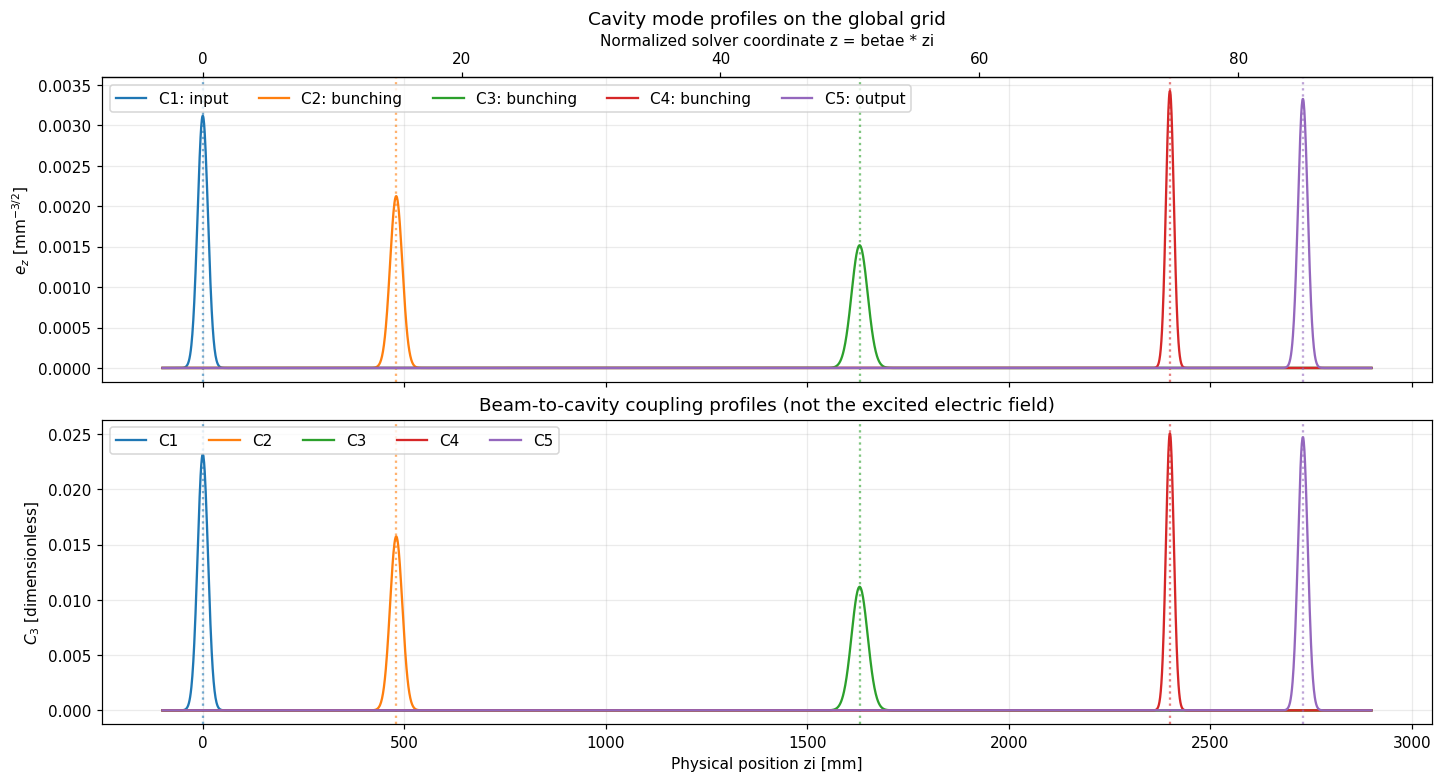

In [4]:
cavity_fields = CavityFields.calculate(
    numerical, cavities, grid, reference, field_maps
)

print("ez.shape =", cavity_fields.ez.shape)
print("C3.shape =", cavity_fields.C3.shape)
print("Columns follow:", cavities.names)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, layout="constrained")
for kk, name in enumerate(cavities.names):
    axes[0].plot(grid.zi, cavity_fields.ez[:, kk], color=colors[kk], label=f"C{kk+1}: {labels[type[kk]]}")
    axes[1].plot(grid.zi, cavity_fields.C3[:, kk], color=colors[kk], label=f"C{kk+1}")
    for ax in axes:
        ax.axvline(zshift[kk], color=colors[kk], linestyle=":", alpha=0.6)

top = axes[0].secondary_xaxis(
    "top", functions=(lambda zi: grid.betae * zi, lambda z: z / grid.betae)
)
top.set_xlabel("Normalized solver coordinate z = betae * zi")
axes[0].set(ylabel=r"$e_z$ [mm$^{-3/2}$]",
            title="Cavity mode profiles on the global grid")
axes[1].set(xlabel="Physical position zi [mm]", ylabel=r"$C_3$ [dimensionless]",
            title="Beam-to-cavity coupling profiles (not the excited electric field)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left", ncol=5)
plt.show()

## 4. Inspect the interpolation cavity by cavity

Each panel overlays the shifted local samples, the samples stored on the solver grid, and the underlying analytical Gaussian.

The cavity center need not coincide with a solver node. Therefore, the maximum sampled value of `ez[:, kk]` need not equal the analytical peak `ezm[kk]` exactly. Both local-map spacing (`N`) and solver spacing (`Nz`) influence the sampled result.

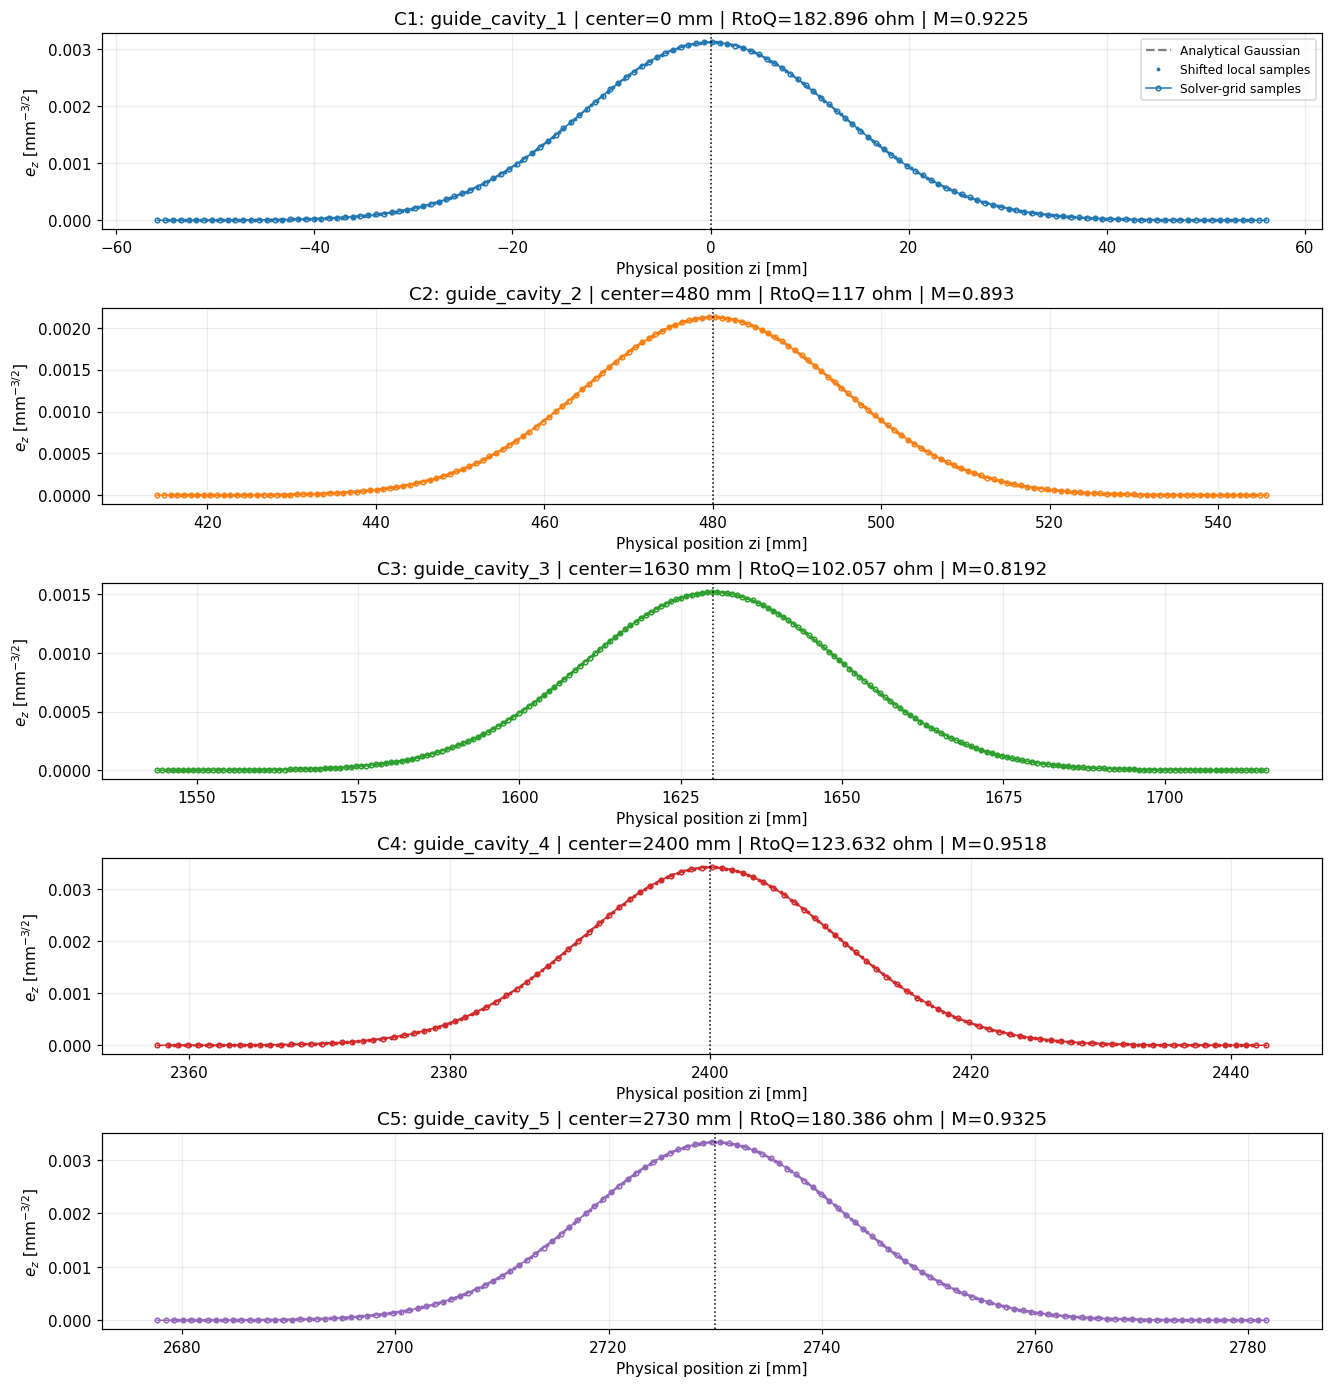

In [5]:
fig, axes = plt.subplots(Nc, 1, figsize=(12, 2.5 * Nc), squeeze=False, layout="constrained")

for kk, name in enumerate(cavities.names):
    ax = axes[kk, 0]
    field_map = field_maps[name]
    positions = field_map.z_mm + zshift[kk]
    selected = (grid.zi >= positions[0] - 2 * grid.dz) & (grid.zi <= positions[-1] + 2 * grid.dz)
    zi_dense = np.linspace(positions[0], positions[-1], 1001)
    ez_dense = ezm[kk] * np.exp(-(k[kk] * 1e-3 * (zi_dense - zshift[kk])) ** 2)

    ax.plot(zi_dense, ez_dense, color="0.5", linestyle="--", label="Analytical Gaussian")
    ax.plot(positions, field_map.e_z, ".", color=colors[kk], markersize=3,
            label="Shifted local samples")
    ax.plot(grid.zi[selected], cavity_fields.ez[selected, kk], "o-", color=colors[kk],
            markersize=3, markerfacecolor="none", linewidth=1, label="Solver-grid samples")
    ax.axvline(zshift[kk], color="black", linestyle=":", linewidth=1)
    ax.set(xlabel="Physical position zi [mm]", ylabel=r"$e_z$ [mm$^{-3/2}$]",
           title=f"C{kk+1}: {name} | center={zshift[kk]:g} mm | RtoQ={RtoQ[kk]:g} ohm | M={M[kk]:g}")
    ax.grid(alpha=0.25)

axes[0, 0].legend(loc="upper right", fontsize=8)
plt.show()

## 5. Check the Gaussian normalization through its integrals

For the infinite Gaussian used in this construction, the input parameters can be recovered from the mode profile:

\[
(R/Q)_{\mathrm{recovered}}
=\frac{\eta_0}{k_0}\left|\int e_z(z_i)\,dz_i\right|^2,
\]
\[
M_{\mathrm{recovered}}
=\frac{\left|\int e_z(z_i)\exp\!\left[-i(k_0/s)(z_i-z_{\mathrm{shift}})\right]dz_i\right|}
{\left|\int e_z(z_i)\,dz_i\right|}.
\]

In these integral formulas, lengths are in **mm** and \(k_0=\mathrm{grid.k0}\) is in **1/mm**. The phase uses each cavity's **resonant** frequency `f0`, not necessarily the operating frequency `f`.

We evaluate the same integrals on the local samples and on the global interpolated profile. Small discrepancies are expected from truncation at \(\pm3/k\), trapezoidal quadrature, zero padding, and interpolation. This checks the Gaussian construction's normalization; it is not a full 3D stored-energy calculation.

The relative-error assertions use `1e-4` locally and `5e-3` on the solver grid for this resolved example. If a map is made narrower or either mesh coarser, a failed test is a reason to inspect resolution, not to change the normalization silently.

In [6]:
RtoQ_local = np.zeros(Nc)
RtoQ_grid = np.zeros(Nc)
M_local = np.zeros(Nc)
M_grid = np.zeros(Nc)

for kk, name in enumerate(cavities.names):
    field_map = field_maps[name]
    ez_integral = np.trapezoid(field_map.e_z, x=field_map.z_mm)
    ez_transit = np.trapezoid(
        field_map.e_z * np.exp(-1j * grid.k0[kk] / reference.s * field_map.z_mm),
        x=field_map.z_mm,
    )
    RtoQ_local[kk] = eta0 / grid.k0[kk] * abs(ez_integral) ** 2
    M_local[kk] = abs(ez_transit) / abs(ez_integral)

    ez_integral = np.trapezoid(cavity_fields.ez[:, kk], x=grid.zi)
    ez_transit = np.trapezoid(
        cavity_fields.ez[:, kk] * np.exp(-1j * grid.k0[kk] / reference.s * (grid.zi - zshift[kk])),
        x=grid.zi,
    )
    RtoQ_grid[kk] = eta0 / grid.k0[kk] * abs(ez_integral) ** 2
    M_grid[kk] = abs(ez_transit) / abs(ez_integral)

show_table(
    ["Cavity", "RtoQ input [ohm]", "Local [ohm]", "Grid [ohm]", "M input", "M local", "M grid"],
    [
        [f"C{kk+1}", f"{RtoQ[kk]:.6f}", f"{RtoQ_local[kk]:.6f}", f"{RtoQ_grid[kk]:.6f}",
         f"{M[kk]:.6f}", f"{M_local[kk]:.6f}", f"{M_grid[kk]:.6f}"]
        for kk in range(Nc)
    ],
)
np.testing.assert_allclose(RtoQ_local, RtoQ, rtol=1e-4, atol=0)
np.testing.assert_allclose(M_local, M, rtol=1e-4, atol=0)
np.testing.assert_allclose(RtoQ_grid, RtoQ, rtol=5e-3, atol=0)
np.testing.assert_allclose(M_grid, M, rtol=5e-3, atol=0)
print(f"Max local RtoQ relative error: {np.max(abs(RtoQ_local / RtoQ - 1)):.3e}")
print(f"Max grid RtoQ relative error:  {np.max(abs(RtoQ_grid / RtoQ - 1)):.3e}")
print(f"Max local M relative error:    {np.max(abs(M_local / M - 1)):.3e}")
print(f"Max grid M relative error:     {np.max(abs(M_grid / M - 1)):.3e}")
print("PASS: local and interpolated normalization integrals.")

| Cavity | RtoQ input [ohm] | Local [ohm] | Grid [ohm] | M input | M local | M grid |
| --- | --- | --- | --- | --- | --- | --- |
| C1 | 182.895900 | 182.887797 | 182.888040 | 0.922500 | 0.922525 | 0.922502 |
| C2 | 116.999900 | 116.994716 | 116.995238 | 0.893000 | 0.893031 | 0.892999 |
| C3 | 102.057000 | 102.052478 | 102.052540 | 0.819200 | 0.819239 | 0.819189 |
| C4 | 123.631800 | 123.626322 | 123.625992 | 0.951800 | 0.951817 | 0.951804 |
| C5 | 180.386400 | 180.378408 | 180.379140 | 0.932500 | 0.932523 | 0.932501 |


Max local RtoQ relative error: 4.431e-05
Max grid RtoQ relative error:  4.697e-05
Max local M relative error:    4.754e-05
Max grid M relative error:     1.286e-05
PASS: local and interpolated normalization integrals.


## 6. Numerical tests: arrays, placement, interpolation, and C3

The following tests use the existing classes without modifying them. The interpolation is independently compared with `np.interp` on the same padded samples. Analytical checks additionally verify the Gaussian values and the conversion to `C3`.

The fields must be entirely inside this test domain, including their zero padding. If you move a cavity or widen its profile, extend `z0, L` as necessary before rerunning.

In [7]:
assert len(field_maps) == Nc
assert tuple(field_maps) == cavities.names
assert cavity_fields.ez.shape == (len(grid.zi), Nc)
assert cavity_fields.C3.shape == (len(grid.zi), Nc)
assert np.all(np.isfinite(cavity_fields.ez))
assert np.all(np.isfinite(cavity_fields.C3))
np.testing.assert_allclose(grid.k0, k0 / 1000.0)

for kk, name in enumerate(cavities.names):
    field_map = field_maps[name]
    assert field_map.z_mm.shape == (N + 1,)
    assert field_map.e_z.shape == (N + 1,)
    assert np.all(np.diff(field_map.z_mm) > 0)
    np.testing.assert_allclose(field_map.z_mm, -field_map.z_mm[::-1], atol=1e-12)
    np.testing.assert_allclose(field_map.e_z, field_map.e_z[::-1], atol=1e-15)
    np.testing.assert_allclose(field_map.z_mm[[0, -1]], [-3000.0 / k[kk], 3000.0 / k[kk]])
    np.testing.assert_allclose(
        field_map.e_z, ezm[kk] * np.exp(-(k[kk] * 1e-3 * field_map.z_mm) ** 2),
        rtol=1e-12, atol=1e-15,
    )
    np.testing.assert_allclose(field_map.e_z[[0, -1]] / ezm[kk], np.exp(-9.0))

    positions = field_map.z_mm + zshift[kk]
    padding = grid.dz / 10.0
    padded_positions = np.r_[positions[0] - 2 * padding, positions[0] - padding,
                             positions, positions[-1] + padding, positions[-1] + 2 * padding]
    padded_fields = np.r_[0.0, 0.0, field_map.e_z, 0.0, 0.0]
    assert padded_positions[0] > grid.zi[0]
    assert padded_positions[-1] < grid.zi[-1]
    ez_expected = np.interp(grid.zi, padded_positions, padded_fields, left=0.0, right=0.0)
    np.testing.assert_allclose(cavity_fields.ez[:, kk], ez_expected, rtol=1e-12, atol=1e-15)

    outside = (grid.zi < padded_positions[0]) | (grid.zi > padded_positions[-1])
    np.testing.assert_array_equal(cavity_fields.ez[outside, kk], np.zeros(np.sum(outside)))

    C3_expected = (
        cavity_fields.ez[:, kk] * eta0 * reference.I0
        / np.sqrt(grid.k0[kk]) / grid.betae / reference.U0 / 1000.0
    )
    np.testing.assert_allclose(cavity_fields.C3[:, kk], C3_expected, rtol=1e-12, atol=1e-15)

# A single-cavity generator call must match its column in the multi-cavity call.
single_map = CavityFieldMap.from_circuit_parameters(
    cavityname=cavities.names[:1], f0=f0[:1], RtoQ=RtoQ[:1],
    M=M[:1], s=reference.s, N=N,
)
np.testing.assert_array_equal(single_map[cavities.names[0]].z_mm, field_maps[cavities.names[0]].z_mm)
np.testing.assert_array_equal(single_map[cavities.names[0]].e_z, field_maps[cavities.names[0]].e_z)

print("PASS: all cavities have the correct shapes, positions, Gaussian values, interpolation, and C3.")
print("PASS: single-cavity and multi-cavity generation agree.")

PASS: all cavities have the correct shapes, positions, Gaussian values, interpolation, and C3.
PASS: single-cavity and multi-cavity generation agree.


## 7. Change RtoQ and M: what changes in the mode shape?

These examples use new field-map objects; the baseline maps are not modified.

- Multiply `RtoQ` by four at fixed `f0, M, s`: the field amplitude doubles, with unchanged local coordinates.
- Increase `M` at fixed `f0, RtoQ, s`: the Gaussian becomes narrower and taller. Its integrated mode voltage remains fixed in the infinite-Gaussian limit.

The second plot varies `M` for the first cavity only; these curves are illustrative alternatives, not additional cavities in the baseline model.

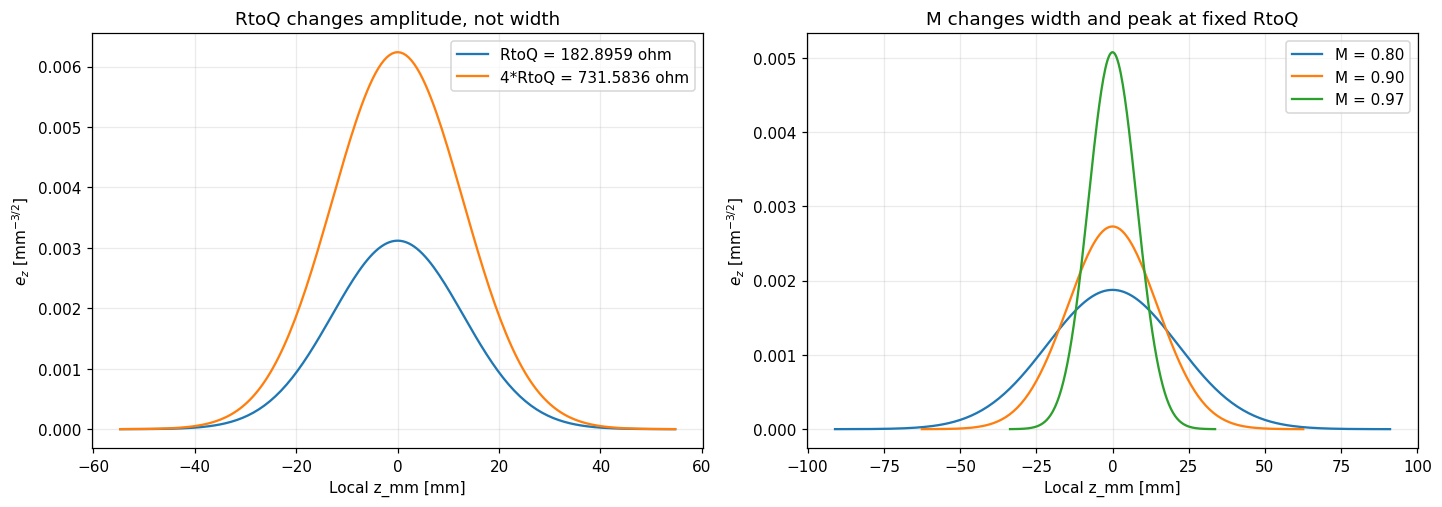

PASS: RtoQ amplitude scaling and fixed-RtoQ M variants.


In [8]:
field_maps_RtoQ = CavityFieldMap.from_circuit_parameters(
    cavityname=cavities.names, f0=f0, RtoQ=4.0 * RtoQ,
    M=M, s=reference.s, N=N,
)
for name in cavities.names:
    np.testing.assert_array_equal(field_maps_RtoQ[name].z_mm, field_maps[name].z_mm)
    np.testing.assert_allclose(field_maps_RtoQ[name].e_z, 2.0 * field_maps[name].e_z)

M_test = np.array([0.80, 0.90, 0.97])
names_test = ("M_080", "M_090", "M_097")
field_maps_M = CavityFieldMap.from_circuit_parameters(
    cavityname=names_test, f0=np.full(3, f0[0]),
    RtoQ=np.full(3, RtoQ[0]), M=M_test, s=reference.s, N=N,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
name = cavities.names[0]
axes[0].plot(field_maps[name].z_mm, field_maps[name].e_z,
             label=f"RtoQ = {RtoQ[0]:.4f} ohm")
axes[0].plot(field_maps_RtoQ[name].z_mm, field_maps_RtoQ[name].e_z,
             label=f"4*RtoQ = {4*RtoQ[0]:.4f} ohm")
axes[0].set_title("RtoQ changes amplitude, not width")

for kk, name in enumerate(names_test):
    field_map = field_maps_M[name]
    axes[1].plot(field_map.z_mm, field_map.e_z, label=f"M = {M_test[kk]:.2f}")
    ez_integral = np.trapezoid(field_map.e_z, x=field_map.z_mm)
    np.testing.assert_allclose(eta0 / grid.k0[0] * ez_integral**2, RtoQ[0], rtol=1e-4)
axes[1].set_title("M changes width and peak at fixed RtoQ")

for ax in axes:
    ax.set(xlabel="Local z_mm [mm]", ylabel=r"$e_z$ [mm$^{-3/2}$]")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()
print("PASS: RtoQ amplitude scaling and fixed-RtoQ M variants.")

## 8. Placement and circuit-parameter independence

Two further checks distinguish a fixed profile from the later operating field:

1. Moving the first cavity by ten solver intervals should translate its interpolated profile by ten rows without changing its shape or the other columns.
2. Changing `Pin`, `Qin`, or `Qext` while holding the supplied normalized maps and reference beam fixed must leave `ez` and `C3` unchanged. These circuit parameters affect the later cavity solution, not this map construction.

The second test does **not** mean the operating electric field is independent of input power or quality factor. It means that this notebook has not solved for the mode excitation yet.

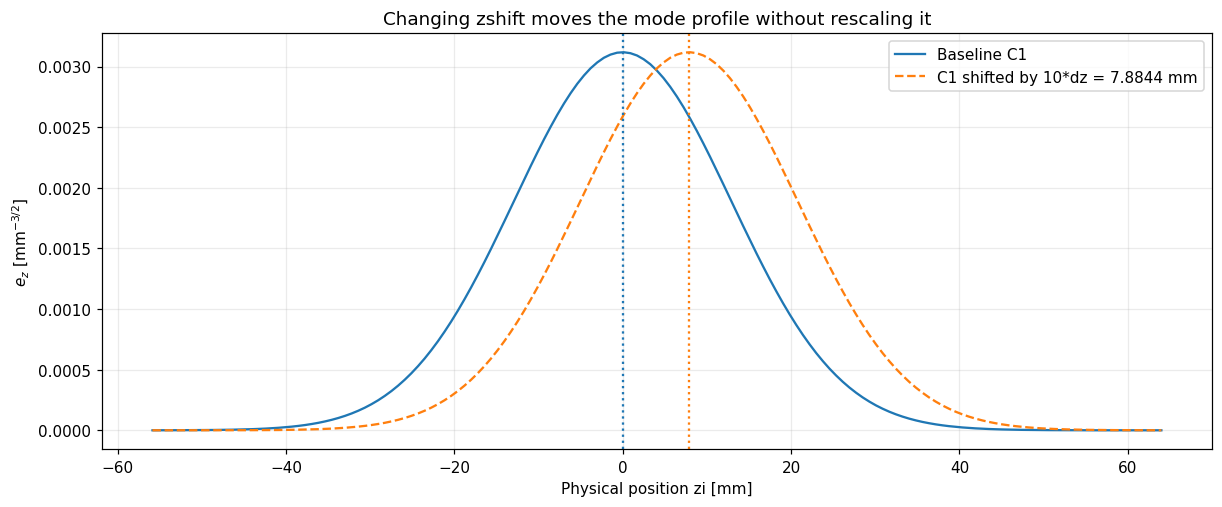

PASS: integer-grid translation and unchanged other cavity columns.
PASS: changing Pin, Qin, and Qext does not alter fixed ez or C3.


In [9]:
zshift_test = zshift.copy()
zshift_test[0] += 10 * grid.dz
cavities_shifted = replace(cavities, zshift=zshift_test)
fields_shifted = CavityFields.calculate(
    numerical, cavities_shifted, grid, reference, field_maps
)
np.testing.assert_allclose(fields_shifted.ez[10:, 0], cavity_fields.ez[:-10, 0],
                           rtol=1e-10, atol=1e-14)
np.testing.assert_array_equal(fields_shifted.ez[:, 1:], cavity_fields.ez[:, 1:])

cavities_changed = replace(cavities, Pin=4.0 * Pin, Qin=2.0 * Qin, Qext=2.0 * Qext)
fields_changed = CavityFields.calculate(
    numerical, cavities_changed, grid, reference, field_maps
)
np.testing.assert_array_equal(fields_changed.ez, cavity_fields.ez)
np.testing.assert_array_equal(fields_changed.C3, cavity_fields.C3)

name = cavities.names[0]
left = field_maps[name].z_mm[0] + zshift[0] - 2 * grid.dz
right = field_maps[name].z_mm[-1] + zshift_test[0] + 2 * grid.dz
selected = (grid.zi >= left) & (grid.zi <= right)
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
ax.plot(grid.zi[selected], cavity_fields.ez[selected, 0], label="Baseline C1")
ax.plot(grid.zi[selected], fields_shifted.ez[selected, 0], "--",
        label=f"C1 shifted by 10*dz = {10*grid.dz:.4f} mm")
ax.axvline(zshift[0], color="tab:blue", linestyle=":")
ax.axvline(zshift_test[0], color="tab:orange", linestyle=":")
ax.set(xlabel="Physical position zi [mm]", ylabel=r"$e_z$ [mm$^{-3/2}$]",
       title="Changing zshift moves the mode profile without rescaling it")
ax.grid(alpha=0.25)
ax.legend()
plt.show()
print("PASS: integer-grid translation and unchanged other cavity columns.")
print("PASS: changing Pin, Qin, and Qext does not alter fixed ez or C3.")

## 9. Local-map resolution: N is not Nz

The local Gaussian is sampled with `N + 1` points before it reaches the solver. Refining `Nz` alone cannot remove errors already introduced by a coarse local map.

This isolated test interpolates the first cavity's local profile onto a fixed dense local axis, without changing the solver grid. It compares `N = 50, 200, 800` against the analytical Gaussian. The plotted error is divided by the analytical peak **only for the error diagnostic**; stored field profiles are not peak-normalized.

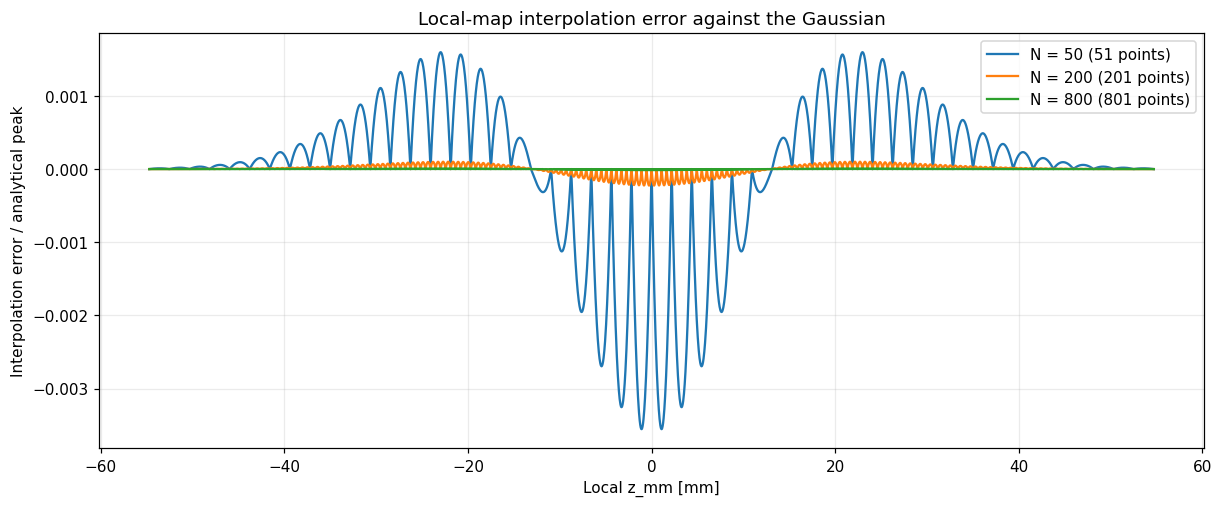

| Local intervals N | Local points | Max abs error / peak |
| --- | --- | --- |
| 50 | 51 | 3.554880e-03 |
| 200 | 201 | 2.248229e-04 |
| 800 | 801 | 1.349941e-05 |


PASS: finer local sampling reduces the interpolation error in this test.


In [10]:
N_test = [50, 200, 800]
z_dense = np.linspace(-3000.0 / k[0], 3000.0 / k[0], 4001)
ez_dense = ezm[0] * np.exp(-(k[0] * 1e-3 * z_dense) ** 2)
errors = []

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for N_value in N_test:
    maps_test = CavityFieldMap.from_circuit_parameters(
        cavityname=cavities.names[:1], f0=f0[:1], RtoQ=RtoQ[:1],
        M=M[:1], s=reference.s, N=N_value,
    )
    field_map = maps_test[cavities.names[0]]
    ez_interpolated = np.interp(z_dense, field_map.z_mm, field_map.e_z)
    error = (ez_interpolated - ez_dense) / ezm[0]
    errors.append(np.max(abs(error)))
    ax.plot(z_dense, error, label=f"N = {N_value} ({N_value + 1} points)")

ax.set(xlabel="Local z_mm [mm]", ylabel="Interpolation error / analytical peak",
       title="Local-map interpolation error against the Gaussian")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

show_table(
    ["Local intervals N", "Local points", "Max abs error / peak"],
    [[N_value, N_value + 1, f"{error:.6e}"] for N_value, error in zip(N_test, errors)],
)
assert errors[2] < errors[1] < errors[0]
print("PASS: finer local sampling reduces the interpolation error in this test.")

## What is ready for the next notebook?

The baseline objects remain available:

- `cavities`: cavity parameters and column ordering.
- `field_maps`: one local `z_mm, e_z` pair per cavity name.
- `grid`: physical and normalized longitudinal coordinates.
- `cavity_fields.ez`: positioned/interpolated energy-normalized profiles.
- `cavity_fields.C3`: profiles used in the beam-excitation integral.
- `beam, reference, numerical`: shared setup.

There are deliberately no `Vnc`, `Vnp`, or `Emz` results here. The next notebook can compare one Python-MATLAB circuit solve using the same profiles and prescribed excitation, then address the conversion from cavity voltage to operating electric field.

No files are exported by running this notebook. The parameter-change examples create separate objects; they do not overwrite the baseline maps or solver fields.